# 02 · Raw census inputs: ACS, LODES, Business Patterns

Step 2, continued: the model's structural inputs (ACS 2020-2024 and LODES 2022) and the POI reference (ZIP and County Business Patterns 2023 with the ZCTA-tract relationship file). Do the files cover every study tract, do their internal totals add up, and what does each one actually measure?

In [1]:
import warnings, os, json, glob
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name in ("eda", "notebooks") else Path.cwd()
os.chdir(ROOT)
import numpy as np, pandas as pd, matplotlib.pyplot as plt, duckdb, pyarrow.parquet as pq
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30); pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
REG = ["maricopa-az", "northern-ca", "eastern-ok", "south-central-tx", "eastern-wa"]
COL = dict(zip(REG, ["#e07b39", "#c0504d", "#6a9e4f", "#3b6fb6", "#8e6bbf"]))

def challenge_root():
    """data/raw/challenge (Windows junctions made by fetch_data.ps1), or the same files in ../MapEquityChallenge/data
    where the junction cannot be followed (e.g. from Linux/WSL)."""
    p = Path("data/raw/challenge")
    try:
        if (p / "reference" / "maricopa-az").is_dir():
            return p
    except OSError:
        pass
    return Path("../MapEquityChallenge/data")
CH = challenge_root(); RAW = Path("data/raw")
TAB, FIG = Path("eda/tables"), Path("eda/figures"); TAB.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
def save(name):
    plt.tight_layout(); plt.savefig(FIG / f"{name}.png", dpi=130, bbox_inches="tight"); plt.show()
con = duckdb.connect(); con.sql("SET threads=4")
study = pd.concat([pd.read_csv(CH / f"reference/{r}/{r}-sample-submission.csv", dtype={"GEOID": str}, usecols=["GEOID"]).assign(region=r) for r in REG])
print("challenge data read from:", CH.resolve(), "| study tracts:", len(study))

challenge data read from: /sessions/rcw-013hmcfk1naa7pch2jpe8lbk/mnt/MapEquityChallenge/data | study tracts: 9794


## 1. ACS 2020-2024: coverage and internal consistency

In [2]:
A = {t: pd.read_parquet(RAW / f"acs/acsdt5y2024-{t}.tracts.parquet") for t in ["b25001", "b25002", "b25024", "b25034", "b01003", "b11001", "b26001"]}
a = study[["GEOID", "region"]]
for t, df in A.items():
    a = a.merge(df, on="GEOID", how="left")
print("national tracts per table:", {t: len(df) for t, df in A.items()}, "| study tracts found:", int(a.B25001_E001.notna().sum()), "of", len(a))
chk = pd.DataFrame({
    "occupied + vacant = housing units (B25002)": (a.B25002_E002 + a.B25002_E003 == a.B25002_E001),
    "B25002 total = B25001": (a.B25002_E001 == a.B25001_E001),
    "units-in-structure categories sum to total (B25024)": (a[[f"B25024_E{i:03d}" for i in range(2, 12)]].sum(axis=1) == a.B25024_E001),
    "year-built categories sum to total (B25034)": (a[[f"B25034_E{i:03d}" for i in range(2, 12)]].sum(axis=1) == a.B25034_E001),
    "households <= housing units": (a.B11001_E001 <= a.B25001_E001),
    "group quarters <= population": (a.B26001_E001 <= a.B01003_E001)})
c = chk.mean().to_frame("share of study tracts passing"); c.to_csv(TAB / "02_acs_consistency.csv"); display(c.style.format("{:.2%}"))
k = a[["B25001_E001", "B01003_E001", "B11001_E001", "B26001_E001"]].rename(columns={"B25001_E001": "housing_units", "B01003_E001": "population", "B11001_E001": "households", "B26001_E001": "group_quarters"})
d = k.describe().T; d["zeros"] = (k == 0).sum(); display(d)
gq = a.assign(gq_share=a.B26001_E001 / a.B01003_E001.replace(0, np.nan))
print("tracts where more than half the residents live in group quarters (prisons, dorms, bases):", int((gq.gq_share > .5).sum()))
print("Only estimates (_E) are kept; ACS margins of error are not used anywhere in the pipeline.")

national tracts per table: {'b25001': 85382, 'b25002': 85382, 'b25024': 85382, 'b25034': 85382, 'b01003': 85382, 'b11001': 85382, 'b26001': 85382} | study tracts found: 9794 of 9794


,share of study tracts passing
occupied + vacant = housing units (B25002),100.00%
B25002 total = B25001,100.00%
units-in-structure categories sum to total (B25024),100.00%
year-built categories sum to total (B25034),100.00%
households <= housing units,100.00%
group quarters <= population,100.00%


,count,mean,std,min,25%,50%,75%,max,zeros
housing_units,9794.0,1746.679,807.701,0.0,1219.0,1645.0,2144.00,13827.0,82
population,9794.0,4264.679,2194.021,0.0,2837.5,3962.0,5275.75,44364.0,51
households,9794.0,1581.615,761.531,0.0,1077.0,1477.0,1954.00,12756.0,85
group_quarters,9794.0,89.167,431.739,0.0,0.0,4.0,42.00,10644.0,4408


tracts where more than half the residents live in group quarters (prisons, dorms, bases): 101
Only estimates (_E) are kept; ACS margins of error are not used anywhere in the pipeline.


**Takeaway.** ACS covers all 9,794 study tracts and is internally consistent: occupied plus vacant equals total housing, and the units-in-structure and year-built categories sum to the total in 100% of tracts. 82 tracts have no housing units and 51 no residents; in 101 tracts more than half of residents live in group quarters (prisons, dormitories, bases), where housing units say little about how many buildings to expect. Only point estimates are used; ACS margins of error, which are large for small tracts, are ignored by the pipeline.

## 2. LODES 2022 workplace jobs: blocks to tracts

,blocks_with_jobs,jobs
state,,
az,"36,998","3,018,413"
ca,"257,557","17,653,890"
nm,"17,161","815,514"
ok,"33,305","1,583,674"
tx,"165,213","12,992,033"
wa,"53,670","3,434,981"


study tracts with no job block at all: 16 | study tracts in New Mexico (state 35): 1


,jobs,median_per_tract,share_zero
region,,,
maricopa-az,"2,866,671",699,0.4%
northern-ca,"1,026,660",853,0.0%
eastern-ok,"1,570,895",700,0.2%
south-central-tx,"11,663,538",855,0.1%
eastern-wa,"680,534",960,0.2%


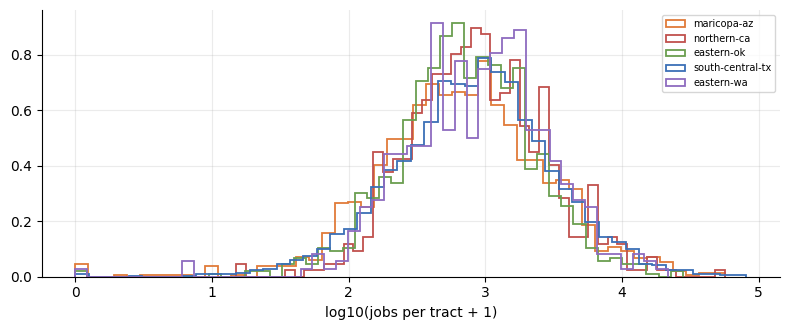

In [3]:
rows, tr = [], []
for st in ["az", "ca", "nm", "ok", "tx", "wa"]:
    l = pd.read_csv(RAW / f"lodes/{st}_wac_S000_JT00_2022.csv.gz", dtype={"w_geocode": str}, usecols=["w_geocode", "C000"])
    rows.append({"state": st, "blocks_with_jobs": len(l), "jobs": l.C000.sum()})
    tr.append(l.assign(GEOID=l.w_geocode.str[:11]).groupby("GEOID").C000.sum())
lo = pd.DataFrame(rows).set_index("state"); display(lo.style.format("{:,.0f}"))
jobs = pd.concat(tr).groupby(level=0).sum()
j = study.assign(jobs=study.GEOID.map(jobs))
print("study tracts with no job block at all:", int(j.jobs.isna().sum()), "| study tracts in New Mexico (state 35):", int(study.GEOID.str.startswith("35").sum()))
jr = j.groupby("region").jobs.agg(["sum", "median", lambda x: (x.fillna(0) == 0).mean()]).reindex(REG); jr.columns = ["jobs", "median_per_tract", "share_zero"]
jr.to_csv(TAB / "02_lodes_by_region.csv"); display(jr.style.format({"jobs": "{:,.0f}", "median_per_tract": "{:,.0f}", "share_zero": "{:.1%}"}))
fig, ax = plt.subplots(figsize=(8, 3.4))
for r in REG:
    ax.hist(np.log10(j.loc[j.region == r, "jobs"].fillna(0) + 1), bins=50, histtype="step", lw=1.3, color=COL[r], label=r, density=True)
ax.set_xlabel("log10(jobs per tract + 1)"); ax.legend(fontsize=7); save("02_lodes_jobs")

**Takeaway.** LODES has 563,904 job blocks in six states; aggregated to tracts, the study totals equal those in the tract table (e.g. 2,866,671 jobs in Maricopa), so the block-to-tract step is exact. 16 study tracts contain no job block. The median tract has 700-960 jobs.

## 3. Business Patterns and the ZCTA-to-tract allocation

ZIP Business Patterns: 34,954 ZIP codes, 8,356,295 establishments
relationship file: 168,212 ZCTA-tract pieces; ZCTAs whose land weights sum to 1 (±0.001): 100.0%; ZCTAs with zero land: 0
ZCTAs present in ZBP: 91.5% (ZIP codes and ZCTAs are not the same thing; PO-box ZIPs have no area)


,tracts,no ZCTA overlap,median ZCTAs per tract
region,,,
maricopa-az,1593,1,1.0
northern-ca,591,0,1.0
eastern-ok,1192,0,2.0
south-central-tx,6003,2,1.0
eastern-wa,415,0,2.0


County Business Patterns totals: 3,192 counties; study counties found: 99.7% of 325


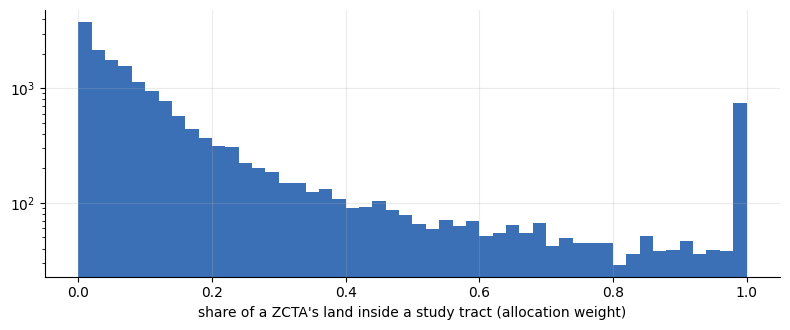

In [4]:
z = pd.read_csv(RAW / "cbp/zbp23totals.txt", dtype={"zip": str}, usecols=["zip", "est", "stabbr"])
rel = pd.read_csv(RAW / "cbp/tab20_zcta520_tract20_natl.txt", sep="|", dtype=str, usecols=["GEOID_ZCTA5_20", "GEOID_TRACT_20", "AREALAND_ZCTA5_20", "AREALAND_PART"])
rel = rel[rel.GEOID_ZCTA5_20.fillna("") != ""].copy()
for c in ["AREALAND_ZCTA5_20", "AREALAND_PART"]: rel[c] = pd.to_numeric(rel[c])
rel["w"] = rel.AREALAND_PART / rel.AREALAND_ZCTA5_20.where(rel.AREALAND_ZCTA5_20 > 0)
wsum = rel.groupby("GEOID_ZCTA5_20").w.sum()
print(f"ZIP Business Patterns: {len(z):,} ZIP codes, {z.est.sum():,.0f} establishments")
print(f"relationship file: {len(rel):,} ZCTA-tract pieces; ZCTAs whose land weights sum to 1 (±0.001): {((wsum - 1).abs() < 1e-3).mean():.1%}; ZCTAs with zero land: {(rel.groupby('GEOID_ZCTA5_20').AREALAND_ZCTA5_20.first() == 0).sum():,}")
zs = rel.merge(z, left_on="GEOID_ZCTA5_20", right_on="zip", how="left")
inzbp = rel.GEOID_ZCTA5_20.isin(z.zip)
print(f"ZCTAs present in ZBP: {rel.loc[inzbp, 'GEOID_ZCTA5_20'].nunique() / rel.GEOID_ZCTA5_20.nunique():.1%} (ZIP codes and ZCTAs are not the same thing; PO-box ZIPs have no area)")
st = study.merge(rel[["GEOID_TRACT_20", "GEOID_ZCTA5_20", "w"]], left_on="GEOID", right_on="GEOID_TRACT_20", how="left")
npz = st.groupby("GEOID").GEOID_ZCTA5_20.nunique()
cov = pd.DataFrame({"tracts": study.groupby("region").size(), "no ZCTA overlap": study.assign(n=study.GEOID.map(npz)).groupby("region").n.apply(lambda x: (x == 0).sum()),
                    "median ZCTAs per tract": study.assign(n=study.GEOID.map(npz)).groupby("region").n.median()}).reindex(REG)
cov.to_csv(TAB / "02_zcta_allocation.csv"); display(cov)
c = pd.read_csv(RAW / "cbp/cbp23co.txt", dtype={"fipstate": str, "fipscty": str, "naics": str}, usecols=["fipstate", "fipscty", "naics", "est"])
tot = c[c.naics.str.startswith("------")]; cty = study.GEOID.str[:5].unique()
print(f"County Business Patterns totals: {len(tot):,} counties; study counties found: {np.isin(cty, (tot.fipstate + tot.fipscty).values).mean():.1%} of {len(cty)}")
fig, ax = plt.subplots(figsize=(8, 3.4)); ax.hist(st.w.dropna(), bins=50, color="#3b6fb6"); ax.set_yscale("log")
ax.set_xlabel("share of a ZCTA's land inside a study tract (allocation weight)"); save("02_zcta_weights")

**Takeaway.** ZIP Business Patterns covers 34,954 ZIP codes (8.4 million establishments). The relationship file is consistent (every ZCTA's land weights sum to 1), but only 91.5% of ZCTAs have a ZIP Business Patterns record, because ZIP codes and ZCTAs are not the same thing. A study tract overlaps a median of 1-2 ZCTAs and 3 tracts overlap none, so each tract's POI reference is mostly one ZCTA's count scaled by land area: a coarse reference, which is one reason POI validation is noisier than building validation. County Business Patterns covers 324 of the 325 study counties (King County, TX, 48269, is absent; one tract).

## Summary

The structural inputs are complete and internally consistent, so modelling errors will not come from the census data themselves. Two limitations follow from the raw files: ACS margins of error are ignored, and the POI reference is allocated by land area from ZIP-level counts. Next: checking how these files are combined into the tract table (03), then exploring that table (04).